# Compare surrogates and transfer to unseen ores

Level: 3. Prerequisites: Levels 1 and 2 in this topic. Reading time: 28 minutes.

## Objectives

Compare model families on identical targets and interpolation rows, inspect whole-case transfer and Gaussian-process coverage, and assess what the evidence says about generalization limits.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

Configure imports and record versions. This makes the method run reproducible.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; `data/derived/learning.json` contains versioned results from 3,072 simulated states across twelve authored circuits, MIT project licence. The target labels are engine outputs, not observed plant data. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

The production portfolio includes Ridge, random forest, histogram gradient boosting, Gaussian process and PyTorch MLP. It records RMSE, MAE and $R^2$ under interpolation, leave-one-case-out and leave-one-ore-group-out protocols. The GP's nominal 95% intervals are checked by empirical coverage. Permutation importance indicates reliance within the test domain, not causation.

## State of the art

Random forests (Breiman, 2001), gradient boosting (Friedman, 2001), Gaussian processes (Rasmussen & Williams, 2006) and Adam-trained neural networks (Kingma & Ba, 2015) are established. OreFlow compares them on a common engine-generated design and audits case/ore-group transfer, per-case scores, interval coverage and out-of-envelope detection. It claims no new algorithm or plant-validated improvement; twelve authored cases bound what the record can support.

Read the committed production evaluation and its declared cases, model identities and split sizes.

In [2]:
# Read the committed production evaluation and its declared cases, model identities and split sizes.
record = json.loads((repo / 'data/derived/learning.json').read_text(encoding='utf-8'))
print('engine version:', record['engine_version'])
print('design:', record['design'])
print('models:', record['models'])
print('interpolation rows:', record['interpolation']['train_rows'], 'train /', record['interpolation']['test_rows'], 'test')
print('case folds:', len(record['leave_one_case_out']), '| group folds:', len(record['leave_one_group_out']))

engine version: 0.10.003
design: {'per_case': 256, 'cases': ['copper_porphyry_soft', 'copper_porphyry_hard', 'gold_free_milling', 'iron_magnetite_fine', 'nickel_sulphide', 'phosphate_clay', 'copper_molybdenum', 'copper_oxide', 'zinc_sulfide', 'mixed_ore_high_clay', 'low_grade_copper', 'refractory_gold'], 'rows': 3072, 'seed': 20260927, 'seconds': 895.4586591999978, 'method': "scrambled Sobol over each case's Contract 1 envelope and ore factors"}
models: ['ridge', 'random_forest', 'hist_gradient_boosting', 'gaussian_process', 'mlp']
interpolation rows: 2460 train / 612 test
case folds: 12 | group folds: 2


Compare recovery errors on the same interpolation rows. Pooled and within-case R² answer different questions.

In [3]:
# Compare recovery errors on the same interpolation rows.
target = 'recovery_pct'
rows = []
for name, values in record['interpolation']['models'].items():
    metric = values[target]
    rows.append({'model': name, 'RMSE (%)': metric['rmse'], 'MAE (%)': metric['mae'],
                 'pooled R²': metric['r2'], 'within-case R²': metric['r2_within_case']})
score = pd.DataFrame(rows).set_index('model').sort_values('RMSE (%)')
display(score.round(3))

,RMSE (%),MAE (%),pooled R²,within-case R²
model,,,,
mlp,3.382,1.675,0.951,0.936
hist_gradient_boosting,4.603,3.178,0.909,0.881
gaussian_process,5.344,3.600,0.878,0.840
random_forest,6.492,4.538,0.820,0.764
ridge,9.460,6.825,0.617,0.498


Plot RMSE by target, retaining target units. Compare models within each column; do not rank recovery, log-upgrade and energy on one raw scale.

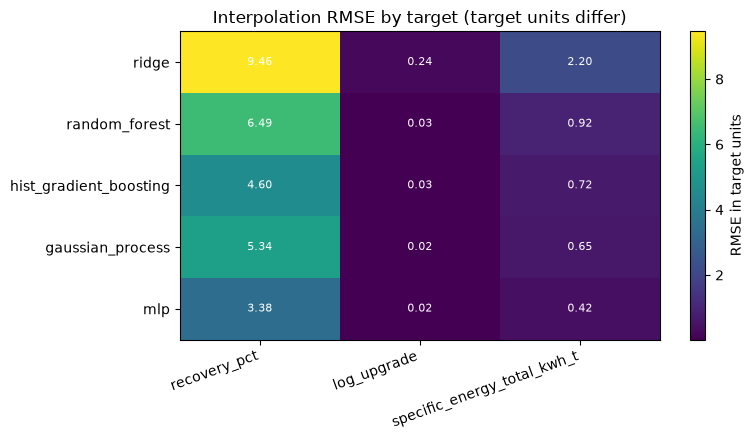

In [4]:
# Plot RMSE by target, retaining target units.
model_names, targets = record['models'], record['targets']
rmse = np.array([[record['interpolation']['models'][m][t]['rmse'] for t in targets] for m in model_names])
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(rmse, aspect='auto', cmap='viridis')
ax.set_xticks(range(len(targets)), targets, rotation=20, ha='right'); ax.set_yticks(range(len(model_names)), model_names)
ax.set_title('Interpolation RMSE by target (target units differ)')
for i in range(len(model_names)):
    for j in range(len(targets)): ax.text(j, i, f'{rmse[i,j]:.2f}', ha='center', va='center', color='white', fontsize=8)
fig.colorbar(im, ax=ax, label='RMSE in target units'); fig.tight_layout()

Inspect whole-case transfer and interval coverage. A strong interpolation result does not promise performance for an ore group absent from training.

In [5]:
# Inspect whole-case transfer and interval coverage.
case_scores = [{'held-out case': f['held_out'], 'RMSE (%)': f['models']['random_forest']['recovery_pct']['rmse']} for f in record['leave_one_case_out']]
group_scores = [{'held-out ore group': f['held_out_group'], 'RMSE (%)': f['models']['random_forest']['recovery_pct']['rmse']} for f in record['leave_one_group_out']]
print('Worst leave-one-case-out recovery scores:')
display(pd.DataFrame(case_scores).sort_values('RMSE (%)', ascending=False).head(5))
print('Leave-one-ore-group-out recovery scores:')
display(pd.DataFrame(group_scores).sort_values('RMSE (%)', ascending=False))
gp = record['interpolation']['models']['gaussian_process']
print('GP nominal 95% interval coverage:', {t: gp[t]['coverage_95'] for t in targets})

Worst leave-one-case-out recovery scores:


,held-out case,RMSE (%)
3,iron_magnetite_fine,48.862763
11,refractory_gold,15.406035
7,copper_oxide,14.117908
2,gold_free_milling,12.480387
8,zinc_sulfide,11.880682


Leave-one-ore-group-out recovery scores:


,held-out ore group,RMSE (%)
0,Cu:chalcopyrite,13.925760
1,Au:pyrite,10.712957


GP nominal 95% interval coverage: {'recovery_pct': 0.9068627450980392, 'log_upgrade': 0.9133986928104575, 'specific_energy_total_kwh_t': 0.9362745098039216}


## Results

Compare the heatmap within each target. The gap between pooled and within-case R² exposes case-mean effects. Whole-case and ore-group holdouts are harder transfer tests, not guarantees for future plants. GP coverage is empirical on this generated split. Every label comes from the same process engine; independent plant data are required for field validation.

## Summary

The bounded result is that the surrogates approximate OreFlow's own engine over twelve authored circuits. The notebook reports how performance changes under stricter holdouts and does not claim general plant predictive capability or a novel learning algorithm.

## References

- https://doi.org/10.1023/A:1010933404324
- https://doi.org/10.1214/aos/1013203451
- https://doi.org/10.48550/arXiv.1412.6980
- https://doi.org/10.1017/CBO9780511790423
- https://doi.org/10.1023/A:1010933404324